In [410]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats



In [411]:
df = pd.read_csv(r"C:\Users\sarth\Downloads\Telegram Desktop\seasonal_agriculture_performance_dataset.csv")
df.head()

,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


In [412]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
df.info()
df.columns

Number of Rows: 4000
Number of Columns: 28
<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   str    
 1   State                          4000 non-null   str    
 2   District                       4000 non-null   str    
 3   Crop                           4000 non-null   str    
 4   Season                         4000 non-null   str    
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha  

Index(['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Farm_Area_Hectares',
       'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct',
       'Sunlight_Hours_Day', 'Soil_pH', 'Soil_Moisture_pct', 'Nitrogen_kg_ha',
       'Phosphorus_kg_ha', 'Potassium_kg_ha', 'Irrigation_Method',
       'Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Seed_Quality_Score',
       'Yield_Tonnes_Ha', 'Production_Tonnes', 'Market_Price_INR_Tonne',
       'Total_Cost_INR', 'Revenue_INR', 'Profit_INR', 'Water_Used_m3',
       'Water_Efficiency_t_per_1000m3', 'Disease_Pest_Risk_pct'],
      dtype='str')

In [413]:
df.describe()
df.describe(include="object")

C:\Users\sarth\AppData\Local\Temp\ipykernel_35504\905123212.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Farm_ID,State,District,Crop,Season,Irrigation_Method
count,4000,4000,4000,4000,4000,4000
unique,4000,8,10,8,3,4
top,SF10001,Andhra Pradesh,Ludhiana,Rice,Kharif,Flood
freq,1,529,427,690,1779,1310


Farm_ID                           0
State                             0
District                          0
Crop                              0
Season                            0
Farm_Area_Hectares                0
Rainfall_mm                      48
Avg_Temperature_C                 0
Humidity_pct                      0
Sunlight_Hours_Day                0
Soil_pH                           0
Soil_Moisture_pct                40
Nitrogen_kg_ha                    0
Phosphorus_kg_ha                  0
Potassium_kg_ha                   0
Irrigation_Method                 0
Fertilizer_kg_ha                  0
Pesticide_Litre_ha                0
Seed_Quality_Score                0
Yield_Tonnes_Ha                  32
Production_Tonnes                 0
Market_Price_INR_Tonne            0
Total_Cost_INR                    0
Revenue_INR                       0
Profit_INR                        0
Water_Used_m3                     0
Water_Efficiency_t_per_1000m3     0
Disease_Pest_Risk_pct       

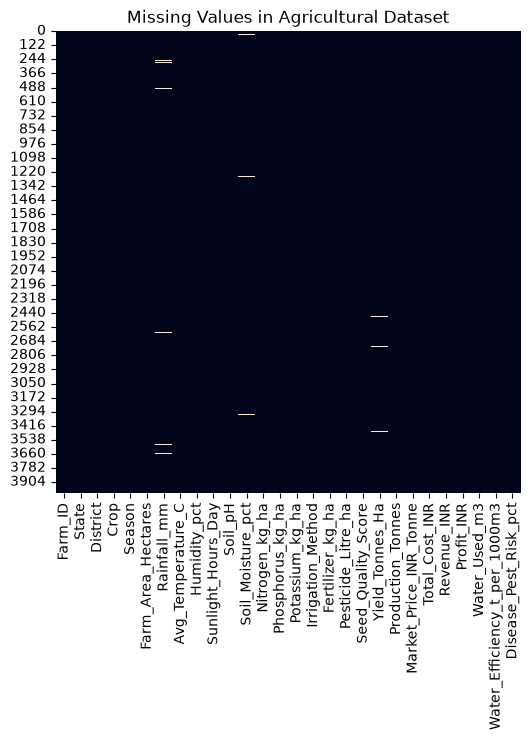

In [414]:
missing = df.isnull().sum()

print(missing)

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

plt.figure(figsize=(6,6))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Agricultural Dataset")
plt.show()

In [415]:
print("Duplicate Records:", df.duplicated().sum())
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Duplicate Records: 0
Dataset Shape After Removing Duplicates: (4000, 28)


In [416]:
for column in df.columns:
    print("\n", column)
    print(df[column].unique()[:20])


 Farm_ID
<StringArray>
['SF10001', 'SF10002', 'SF10003', 'SF10004', 'SF10005', 'SF10006', 'SF10007',
 'SF10008', 'SF10009', 'SF10010', 'SF10011', 'SF10012', 'SF10013', 'SF10014',
 'SF10015', 'SF10016', 'SF10017', 'SF10018', 'SF10019', 'SF10020']
Length: 20, dtype: str

 State
<StringArray>
['Andhra Pradesh',    'Maharashtra',      'Telangana',      'Karnataka',
        'Gujarat',     'Tamil Nadu',         'Punjab', 'Madhya Pradesh']
Length: 8, dtype: str

 District
<StringArray>
[  'Rajkot', 'Nalgonda', 'Warangal',   'Indore', 'Ludhiana',  'Raichur',
   'Guntur',  'Krishna',   'Nashik',    'Erode']
Length: 10, dtype: str

 Crop
<StringArray>
[    'Wheat',     'Maize',    'Pulses',      'Rice',    'Cotton',    'Chilli',
 'Groundnut', 'Sugarcane']
Length: 8, dtype: str

 Season
<StringArray>
['Kharif', 'Rabi', 'Zaid']
Length: 3, dtype: str

 Farm_Area_Hectares
[ 0.53  6.53  4.86  4.5   4.21  5.46  8.13  5.34  6.98 13.69  4.7  14.07
  6.04 10.5   4.38  2.26  3.93 11.04  2.46 14.48]

 Rai

In [417]:
print(df["Season"].value_counts())


Season
Kharif    1779
Rabi      1627
Zaid       594
Name: count, dtype: int64


Season
Kharif    1779
Rabi      1627
Zaid       594
Name: count, dtype: int64


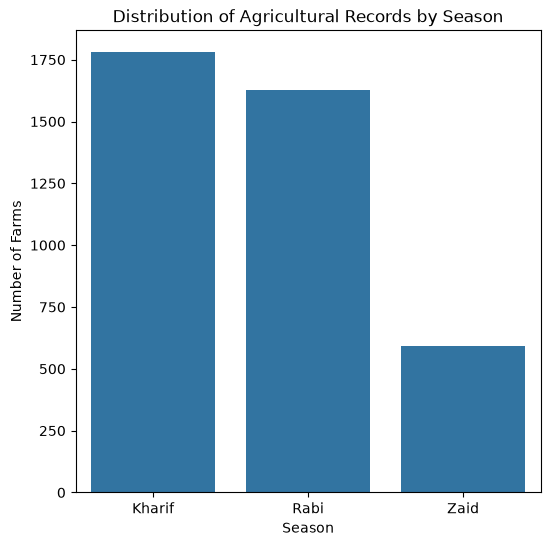

In [418]:
print(df["Season"].value_counts())

plt.figure(figsize=(6,6))

sns.countplot(data=df, x="Season")

plt.title("Distribution of Agricultural Records by Season")
plt.xlabel("Season")
plt.ylabel("Number of Farms")

plt.show()

Crop
Rice         690
Wheat        614
Maize        551
Cotton       508
Pulses       496
Groundnut    424
Chilli       412
Sugarcane    305
Name: count, dtype: int64


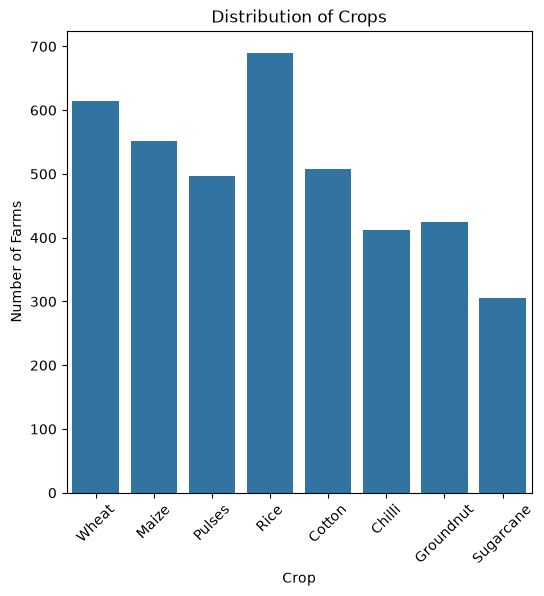

In [419]:
print(df["Crop"].value_counts())

plt.figure(figsize=(6,6))

sns.countplot(data=df, x="Crop")

plt.title("Distribution of Crops")
plt.xlabel("Crop")
plt.ylabel("Number of Farms")

plt.xticks(rotation=45)

plt.show()

State
Andhra Pradesh    529
Telangana         516
Maharashtra       512
Madhya Pradesh    497
Karnataka         489
Gujarat           488
Tamil Nadu        485
Punjab            484
Name: count, dtype: int64


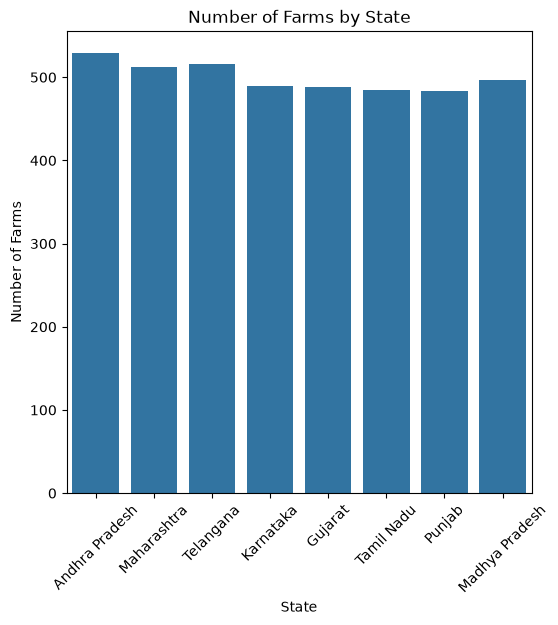

In [420]:
print(df["State"].value_counts())

plt.figure(figsize=(6,6))

sns.countplot(data=df, x="State")

plt.title("Number of Farms by State")
plt.xlabel("State")
plt.ylabel("Number of Farms")

plt.xticks(rotation=45)

plt.show()

In [421]:
season_summary = df.groupby("Season").agg({
    "Yield_Tonnes_Ha": "mean",
    "Production_Tonnes": "mean",
    "Revenue_INR": "mean",
    "Profit_INR": "mean",
    "Water_Used_m3": "mean",
    "Disease_Pest_Risk_pct": "mean"
})

season_summary

,Yield_Tonnes_Ha,Production_Tonnes,Revenue_INR,Profit_INR,Water_Used_m3,Disease_Pest_Risk_pct
Season,,,,,,
Kharif,5.643973,46.311192,710719.055649,178914.647555,6102.201237,54.467903
Rabi,5.080498,41.486712,601526.048556,87689.470191,5846.987093,40.482114
Zaid,4.665942,38.886111,519171.904040,-24804.824916,6419.893939,38.216667


Season
Kharif    5.643973
Rabi      5.080498
Zaid      4.665942
Name: Yield_Tonnes_Ha, dtype: float64


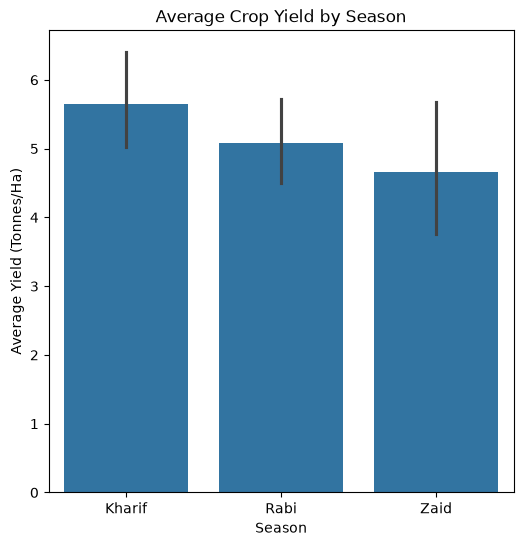

In [422]:
yield_season = df.groupby("Season")["Yield_Tonnes_Ha"].mean()

print(yield_season)

plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Season",
    y="Yield_Tonnes_Ha",
    estimator="mean"
)

plt.title("Average Crop Yield by Season")
plt.xlabel("Season")
plt.ylabel("Average Yield (Tonnes/Ha)")

plt.show()


Season
Kharif    46.311192
Rabi      41.486712
Zaid      38.886111
Name: Production_Tonnes, dtype: float64


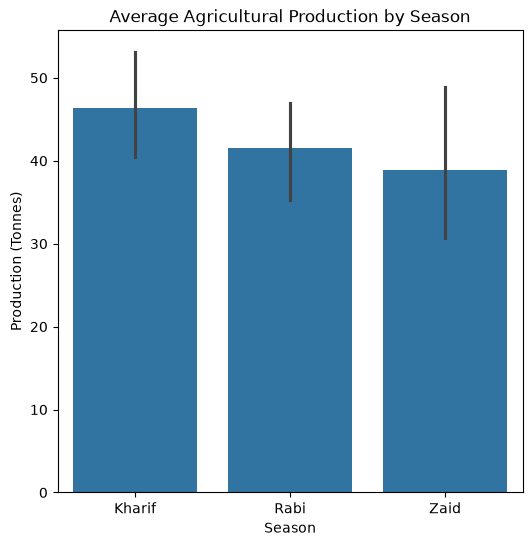

In [423]:
production_season = df.groupby("Season")["Production_Tonnes"].mean()

print(production_season)

plt.figure(figsize=(6, 6))

sns.barplot(
    data=df,
    x="Season",
    y="Production_Tonnes",
    estimator="mean"
)

plt.title("Average Agricultural Production by Season")
plt.xlabel("Season")
plt.ylabel("Production (Tonnes)")

plt.show()

Season
Kharif    710719.055649
Rabi      601526.048556
Zaid      519171.904040
Name: Revenue_INR, dtype: float64


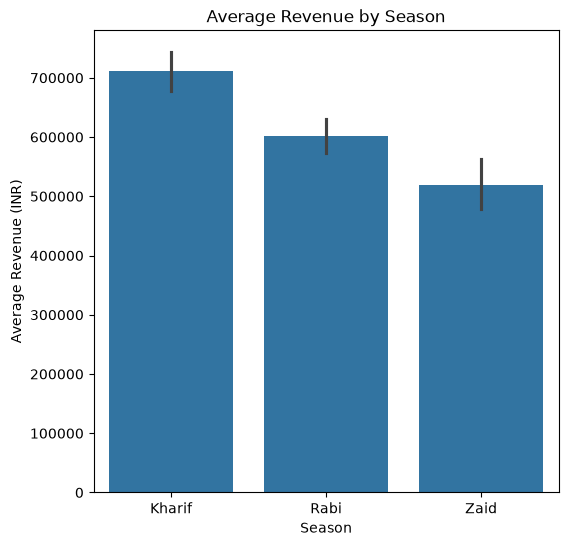

In [424]:
revenue_season = df.groupby("Season")["Revenue_INR"].mean()

print(revenue_season)

plt.figure(figsize=(6, 6))

sns.barplot(
    data=df,
    x="Season",
    y="Revenue_INR",
    estimator="mean"
)

plt.title("Average Revenue by Season")
plt.xlabel("Season")
plt.ylabel("Average Revenue (INR)")

plt.show()

Season
Kharif    178914.647555
Rabi       87689.470191
Zaid      -24804.824916
Name: Profit_INR, dtype: float64


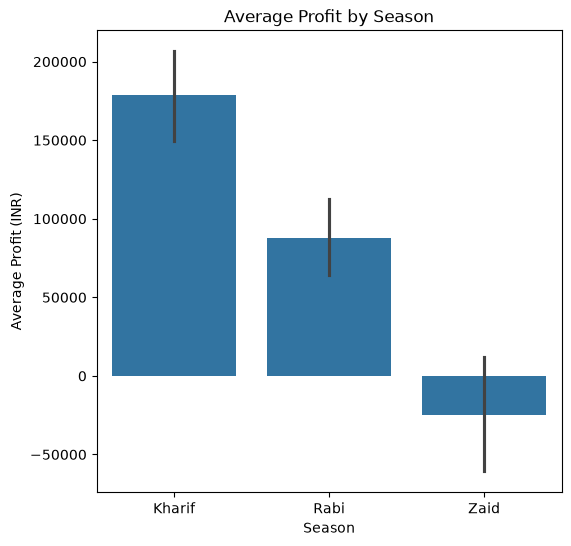

In [425]:
profit_season = df.groupby("Season")["Profit_INR"].mean()

print(profit_season)

plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Season",
    y="Profit_INR",
    estimator="mean"
)

plt.title("Average Profit by Season")
plt.xlabel("Season")
plt.ylabel("Average Profit (INR)")

plt.show()

Season
Kharif    6102.201237
Rabi      5846.987093
Zaid      6419.893939
Name: Water_Used_m3, dtype: float64


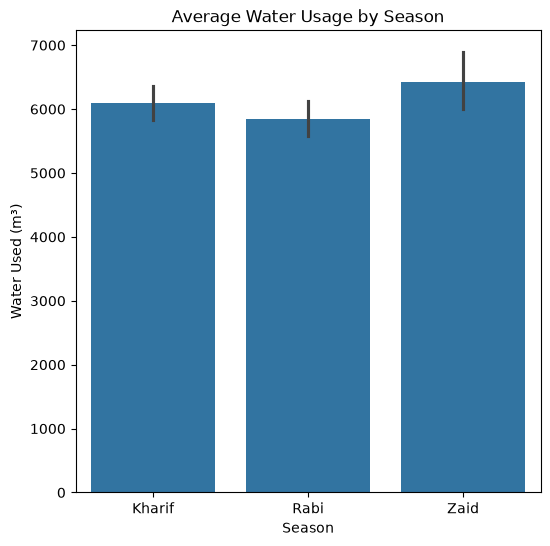

In [426]:
water_season = df.groupby("Season")["Water_Used_m3"].mean()

print(water_season)

plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Season",
    y="Water_Used_m3",
    estimator="mean"
)

plt.title("Average Water Usage by Season")
plt.xlabel("Season")
plt.ylabel("Water Used (m³)")

plt.show()

Season
Kharif    5.891834
Rabi      5.186122
Zaid      4.413239
Name: Water_Efficiency_t_per_1000m3, dtype: float64


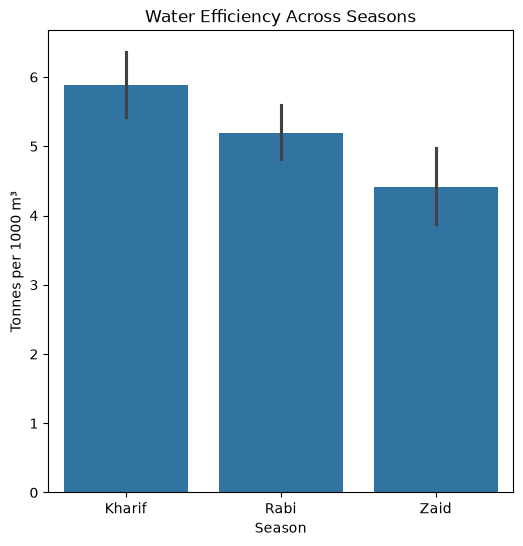

In [427]:
water_efficiency = df.groupby("Season")[
    "Water_Efficiency_t_per_1000m3"
].mean()

print(water_efficiency)

plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Season",
    y="Water_Efficiency_t_per_1000m3",
    estimator="mean"
)

plt.title("Water Efficiency Across Seasons")
plt.xlabel("Season")
plt.ylabel("Tonnes per 1000 m³")

plt.show()

Season
Kharif    852.084205
Rabi      436.000124
Zaid      299.421784
Name: Rainfall_mm, dtype: float64


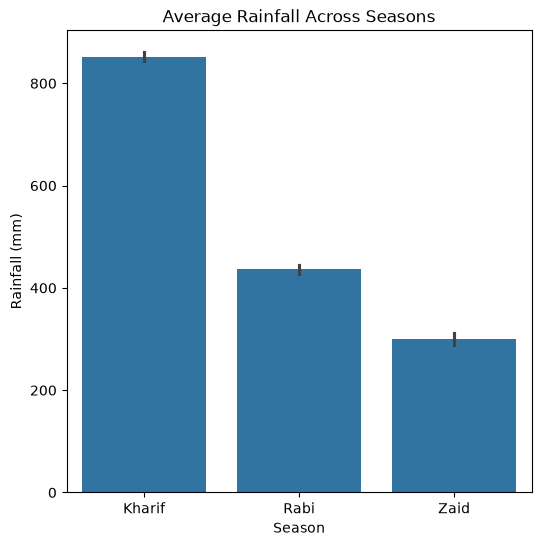

In [428]:
rainfall_season = df.groupby("Season")["Rainfall_mm"].mean()

print(rainfall_season)

plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Season",
    y="Rainfall_mm",
    estimator="mean"
)

plt.title("Average Rainfall Across Seasons")
plt.xlabel("Season")
plt.ylabel("Rainfall (mm)")

plt.show()

Season
Kharif    28.454019
Rabi      23.489183
Zaid      31.042088
Name: Avg_Temperature_C, dtype: float64


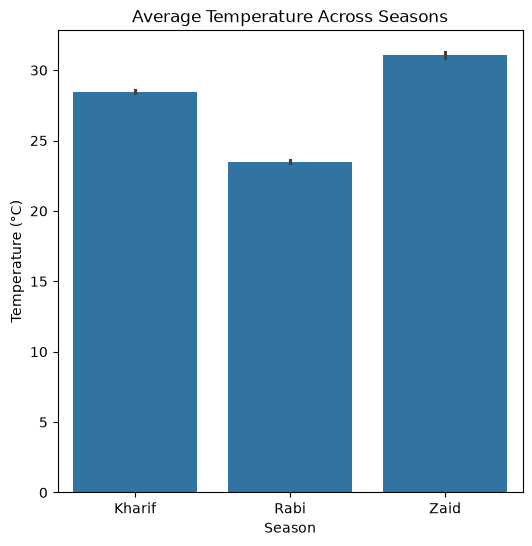

In [429]:
temperature_season = df.groupby("Season")[
    "Avg_Temperature_C"
].mean()

print(temperature_season)
plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Season",
    y="Avg_Temperature_C",
    estimator="mean"
)

plt.title("Average Temperature Across Seasons")
plt.xlabel("Season")
plt.ylabel("Temperature (°C)")

plt.show()

Season
Kharif    71.812591
Rabi      57.893178
Zaid      52.012121
Name: Humidity_pct, dtype: float64


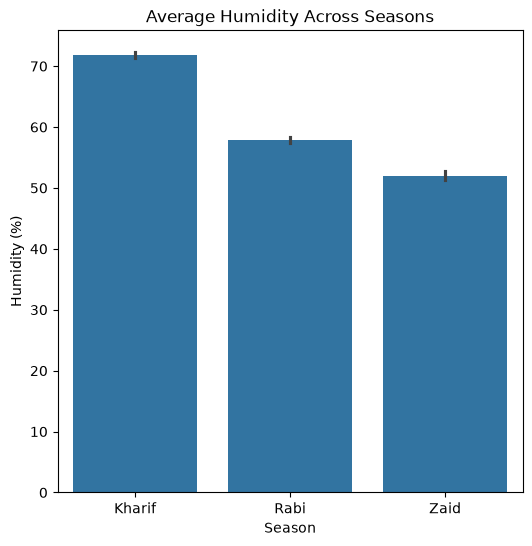

In [430]:
humidity_season = df.groupby("Season")["Humidity_pct"].mean()

print(humidity_season)

plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Season",
    y="Humidity_pct",
    estimator="mean"
)

plt.title("Average Humidity Across Seasons")
plt.xlabel("Season")
plt.ylabel("Humidity (%)")

plt.show()

Season
Kharif    31.198410
Rabi      24.050620
Zaid      19.170085
Name: Soil_Moisture_pct, dtype: float64


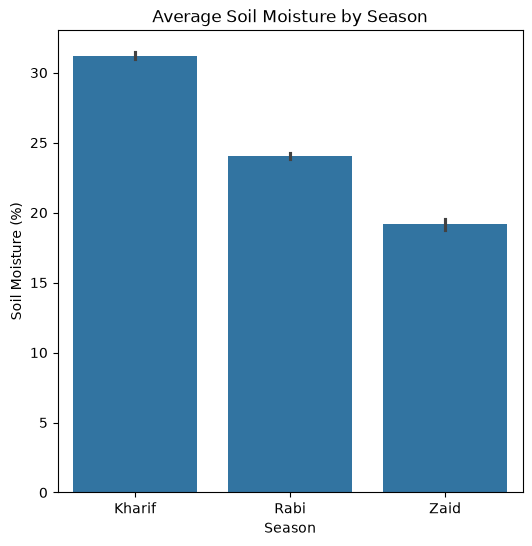

In [431]:
soil_moisture = df.groupby("Season")[
    "Soil_Moisture_pct"
].mean()

print(soil_moisture)

plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Season",
    y="Soil_Moisture_pct",
    estimator="mean"
)

plt.title("Average Soil Moisture by Season")
plt.xlabel("Season")
plt.ylabel("Soil Moisture (%)")

plt.show()

Season
Kharif    187.077965
Rabi      185.407068
Zaid      184.638047
Name: Fertilizer_kg_ha, dtype: float64


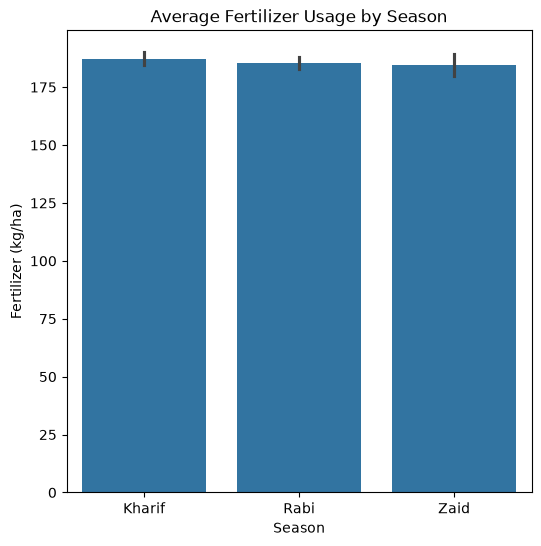

In [432]:
fertilizer_season = df.groupby("Season")[
    "Fertilizer_kg_ha"
].mean()

print(fertilizer_season)

plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Season",
    y="Fertilizer_kg_ha",
    estimator="mean"
)

plt.title("Average Fertilizer Usage by Season")
plt.xlabel("Season")
plt.ylabel("Fertilizer (kg/ha)")

plt.show()

Season
Kharif    5.079747
Rabi      5.024690
Zaid      5.171212
Name: Pesticide_Litre_ha, dtype: float64


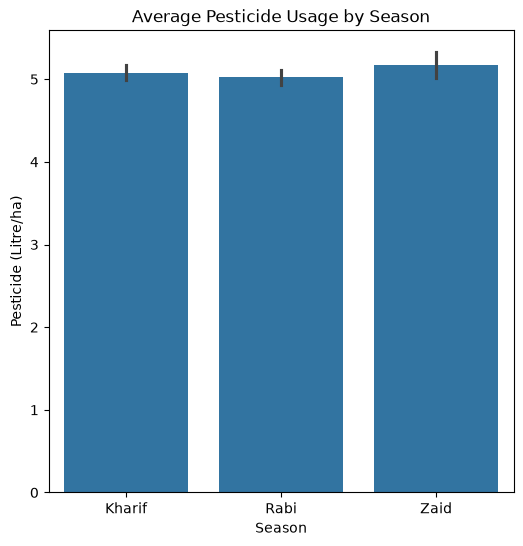

In [433]:
pesticide_season = df.groupby("Season")[
    "Pesticide_Litre_ha"
].mean()

print(pesticide_season)

plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Season",
    y="Pesticide_Litre_ha",
    estimator="mean"
)

plt.title("Average Pesticide Usage by Season")
plt.xlabel("Season")
plt.ylabel("Pesticide (Litre/ha)")

plt.show()

Season
Kharif    54.467903
Rabi      40.482114
Zaid      38.216667
Name: Disease_Pest_Risk_pct, dtype: float64


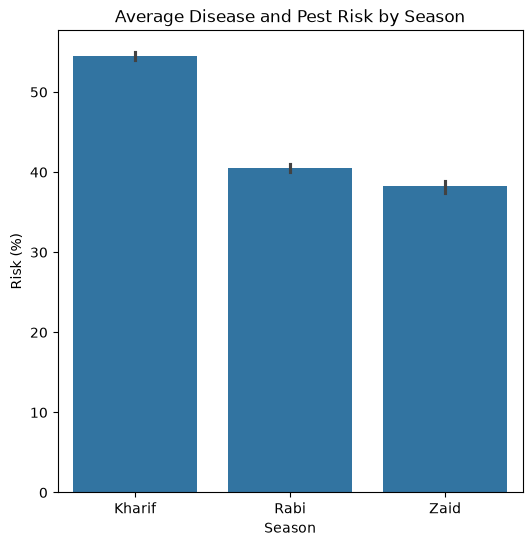

In [434]:
risk_season = df.groupby("Season")[
    "Disease_Pest_Risk_pct"
].mean()

print(risk_season)

plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Season",
    y="Disease_Pest_Risk_pct",
    estimator="mean"
)

plt.title("Average Disease and Pest Risk by Season")
plt.xlabel("Season")
plt.ylabel("Risk (%)")

plt.show()

Season
Kharif    0.821613
Rabi      0.832170
Zaid      0.823165
Name: Seed_Quality_Score, dtype: float64


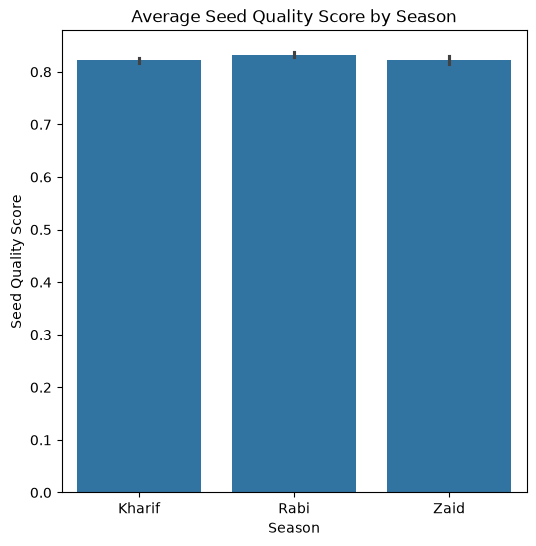

In [435]:
seed_quality = df.groupby("Season")[
    "Seed_Quality_Score"
].mean()

print(seed_quality)

plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Season",
    y="Seed_Quality_Score",
    estimator="mean"
)

plt.title("Average Seed Quality Score by Season")
plt.xlabel("Season")
plt.ylabel("Seed Quality Score")

plt.show()

Irrigation_Method
Flood        1310
Rainfed      1041
Drip          915
Sprinkler     734
Name: count, dtype: int64


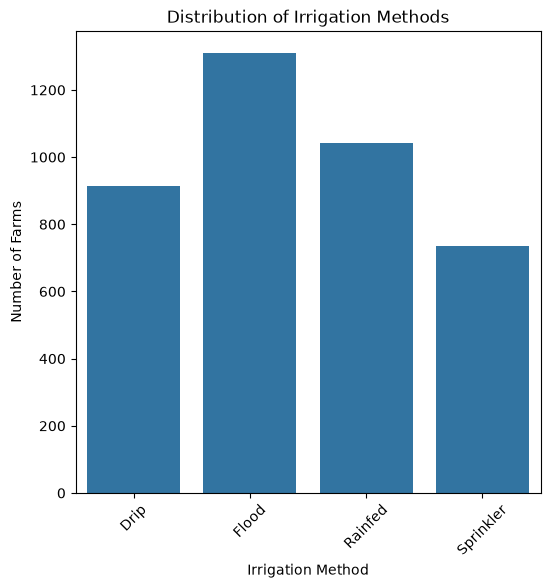

In [436]:
print(df["Irrigation_Method"].value_counts())

plt.figure(figsize=(6,6))

sns.countplot(
    data=df,
    x="Irrigation_Method"
)

plt.title("Distribution of Irrigation Methods")
plt.xlabel("Irrigation Method")
plt.ylabel("Number of Farms")

plt.xticks(rotation=45)

plt.show()

Irrigation_Method
Drip         6.620662
Sprinkler    5.188819
Flood        4.897724
Rainfed      4.613182
Name: Yield_Tonnes_Ha, dtype: float64


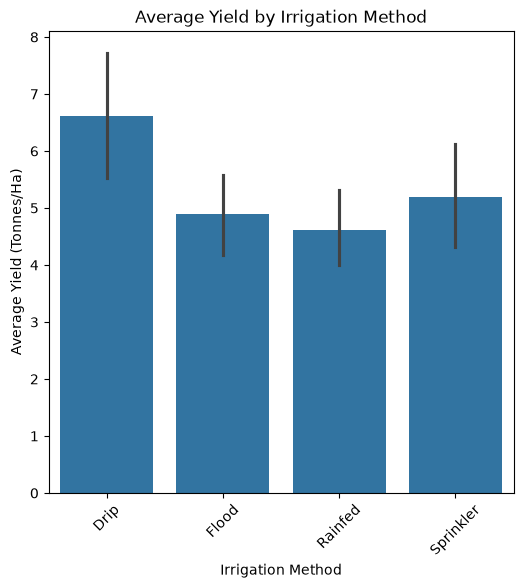

In [437]:
irrigation_yield = df.groupby(
    "Irrigation_Method"
)["Yield_Tonnes_Ha"].mean()

print(irrigation_yield.sort_values(ascending=False))

plt.figure(figsize=(6,6))

sns.barplot(
    data=df,
    x="Irrigation_Method",
    y="Yield_Tonnes_Ha",
    estimator="mean"
)

plt.title("Average Yield by Irrigation Method")
plt.xlabel("Irrigation Method")
plt.ylabel("Average Yield (Tonnes/Ha)")

plt.xticks(rotation=45)

plt.show()

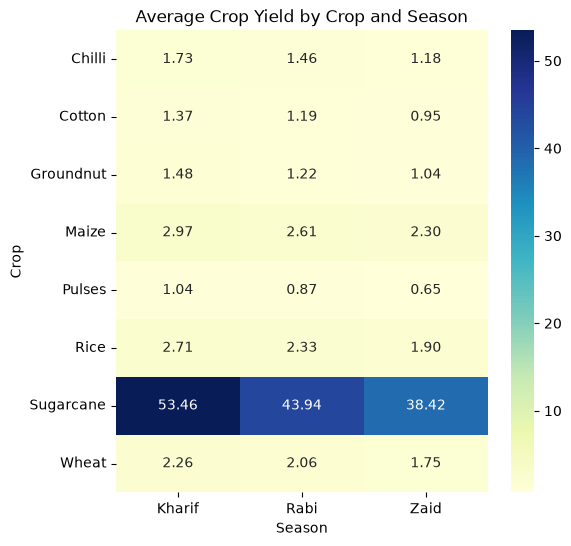

In [438]:
crop_season = pd.pivot_table(
    df,
    values="Yield_Tonnes_Ha",
    index="Crop",
    columns="Season",
    aggfunc="mean"
)

crop_season

plt.figure(figsize=(6,6))

sns.heatmap(
    crop_season,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Average Crop Yield by Crop and Season")

plt.xlabel("Season")
plt.ylabel("Crop")

plt.show()

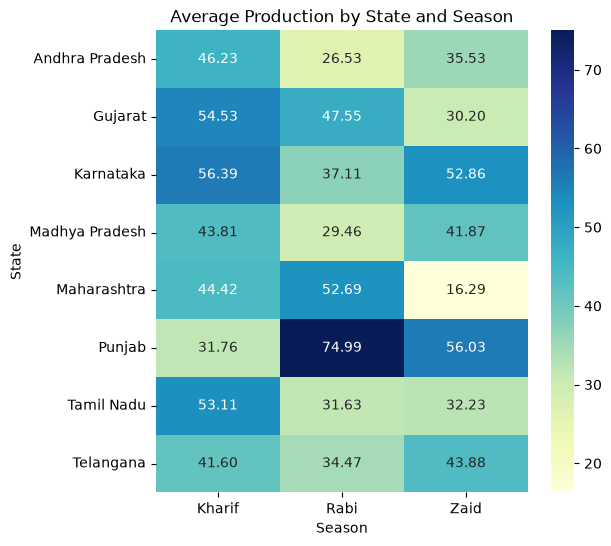

In [439]:
state_season = pd.pivot_table(
    df,
    values="Production_Tonnes",
    index="State",
    columns="Season",
    aggfunc="mean"
)

state_season

plt.figure(figsize=(6,6))

sns.heatmap(
    state_season,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Average Production by State and Season")

plt.xlabel("Season")
plt.ylabel("State")

plt.show()

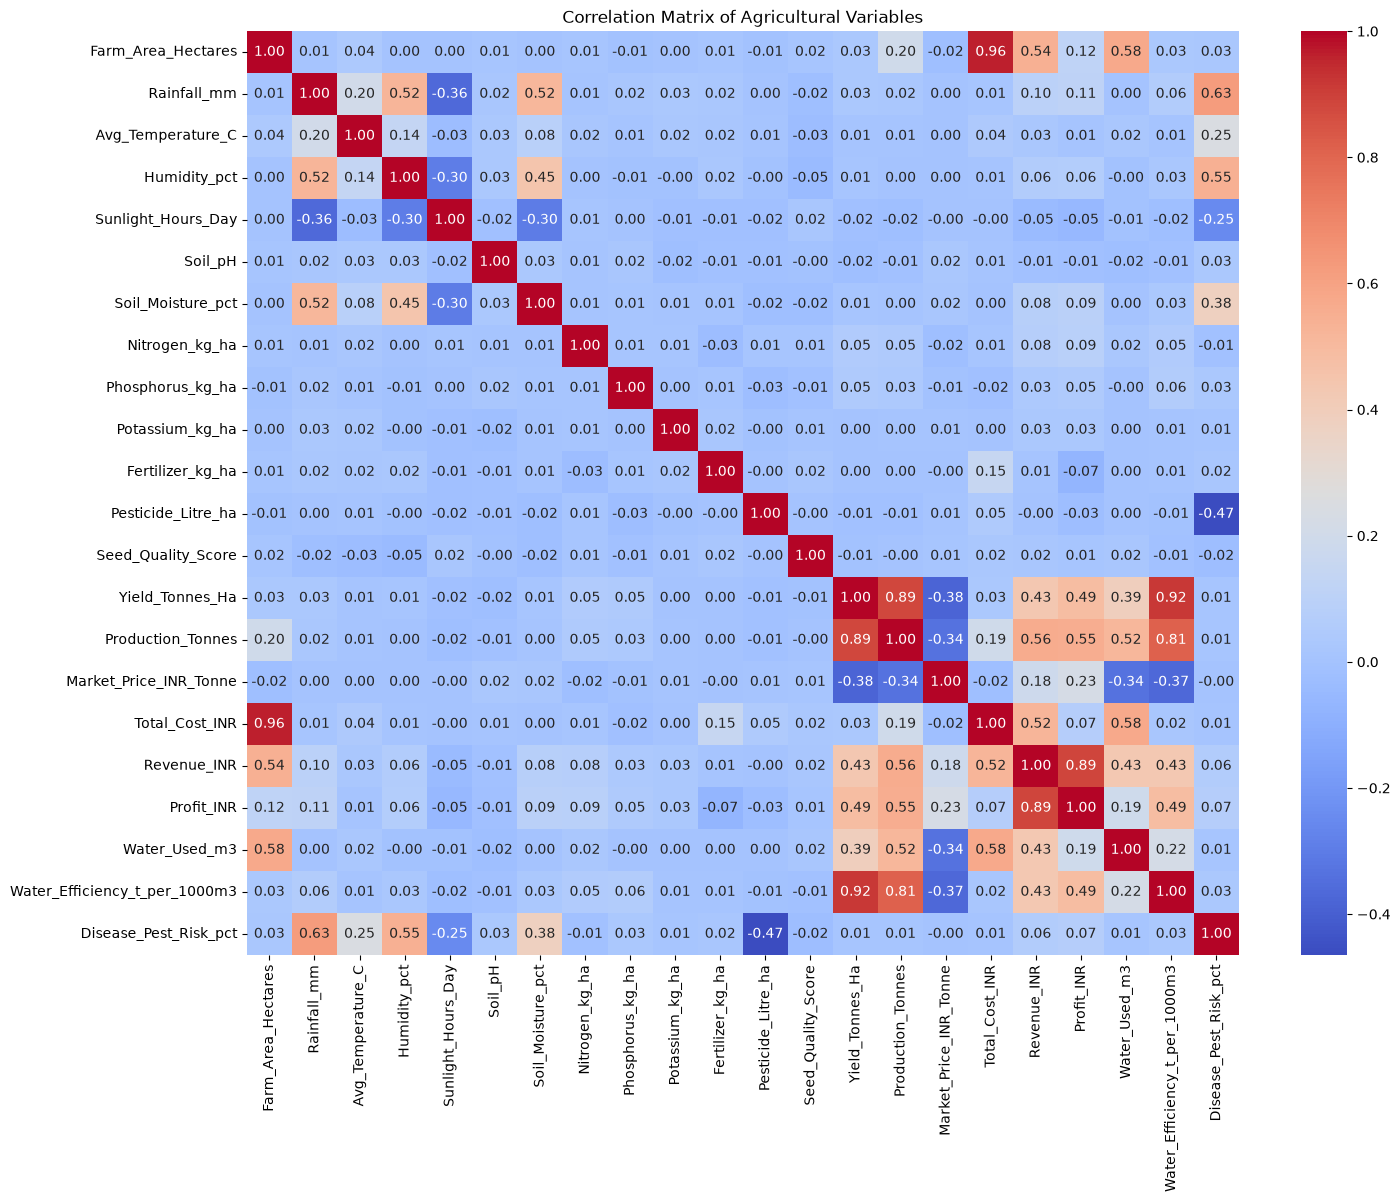

In [440]:
numeric_columns = df.select_dtypes(
    include=np.number
)

correlation = numeric_columns.corr()

correlation

plt.figure(figsize=(16,12))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix of Agricultural Variables")

plt.show()

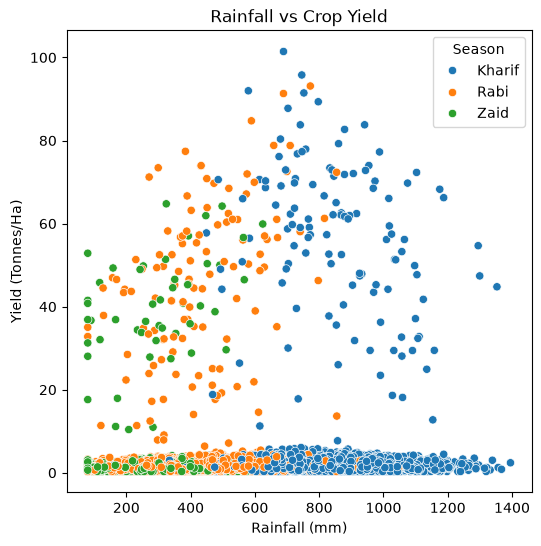

In [441]:
plt.figure(figsize=(6,6))

sns.scatterplot(
    data=df,
    x="Rainfall_mm",
    y="Yield_Tonnes_Ha",
    hue="Season"
)

plt.title("Rainfall vs Crop Yield")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Yield (Tonnes/Ha)")

plt.show()

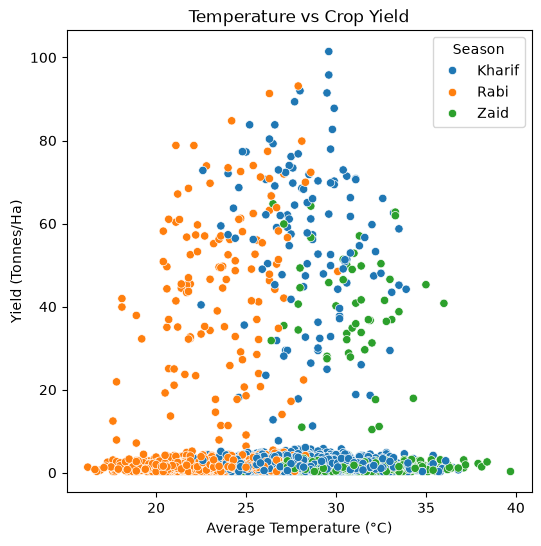

In [442]:
plt.figure(figsize=(6,6))

sns.scatterplot(
    data=df,
    x="Avg_Temperature_C",
    y="Yield_Tonnes_Ha",
    hue="Season"
)

plt.title("Temperature vs Crop Yield")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Yield (Tonnes/Ha)")

plt.show()

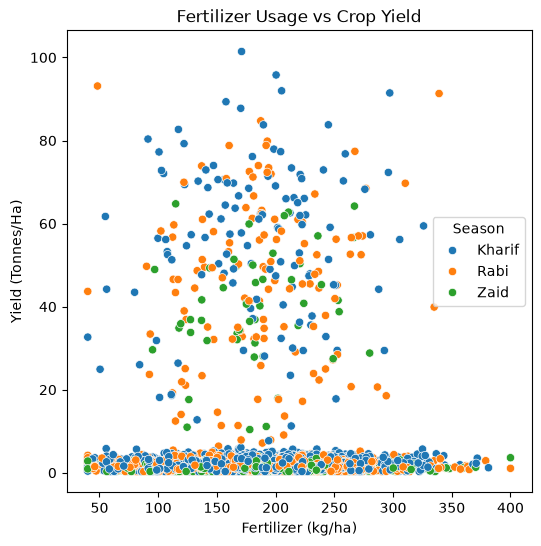

In [443]:
plt.figure(figsize=(6,6))

sns.scatterplot(
    data=df,
    x="Fertilizer_kg_ha",
    y="Yield_Tonnes_Ha",
    hue="Season"
)

plt.title("Fertilizer Usage vs Crop Yield")
plt.xlabel("Fertilizer (kg/ha)")
plt.ylabel("Yield (Tonnes/Ha)")

plt.show()

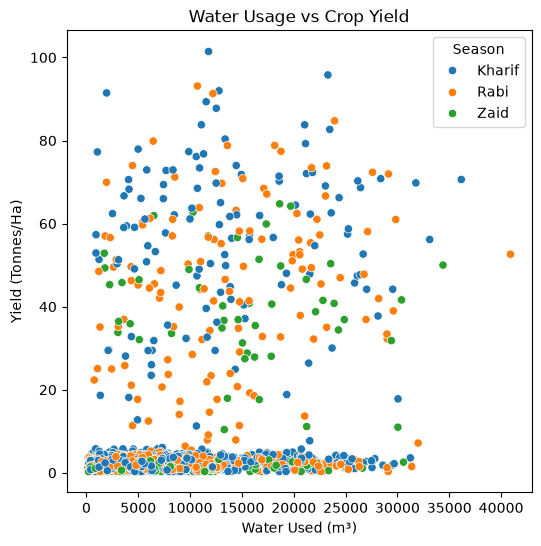

In [444]:
plt.figure(figsize=(6,6))

sns.scatterplot(
    data=df,
    x="Water_Used_m3",
    y="Yield_Tonnes_Ha",
    hue="Season"
)

plt.title("Water Usage vs Crop Yield")
plt.xlabel("Water Used (m³)")
plt.ylabel("Yield (Tonnes/Ha)")

plt.show()

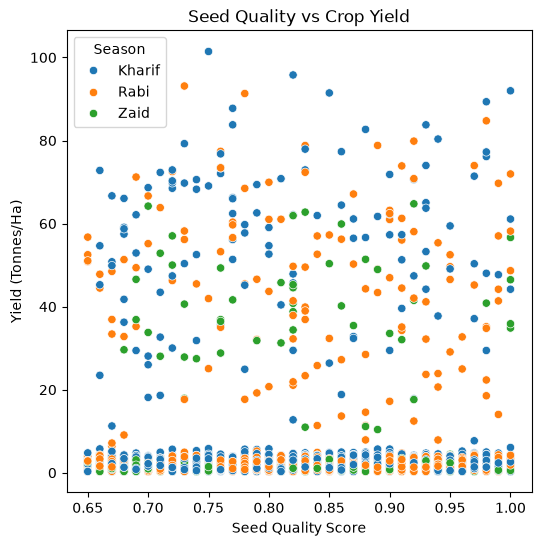

In [445]:
plt.figure(figsize=(6,6))

sns.scatterplot(
    data=df,
    x="Seed_Quality_Score",
    y="Yield_Tonnes_Ha",
    hue="Season"
)

plt.title("Seed Quality vs Crop Yield")
plt.xlabel("Seed Quality Score")
plt.ylabel("Yield (Tonnes/Ha)")

plt.show()

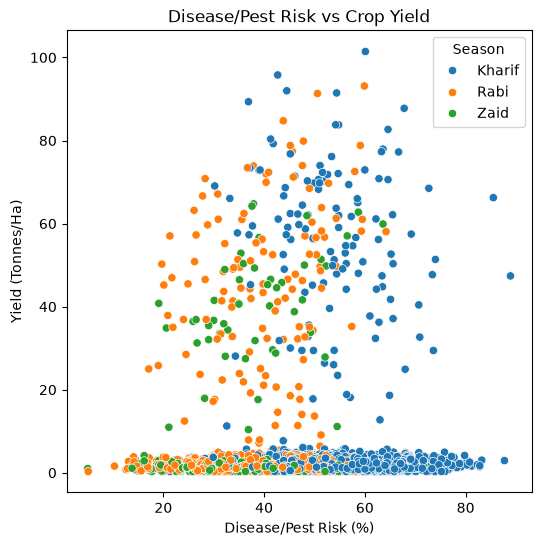

In [446]:
plt.figure(figsize=(6,6))

sns.scatterplot(
    data=df,
    x="Disease_Pest_Risk_pct",
    y="Yield_Tonnes_Ha",
    hue="Season"
)

plt.title("Disease/Pest Risk vs Crop Yield")
plt.xlabel("Disease/Pest Risk (%)")
plt.ylabel("Yield (Tonnes/Ha)")

plt.show()

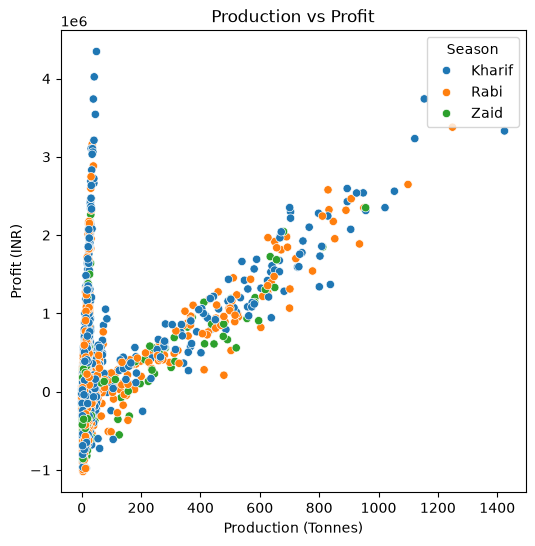

In [447]:
plt.figure(figsize=(6,6))

sns.scatterplot(
    data=df,
    x="Production_Tonnes",
    y="Profit_INR",
    hue="Season"
)

plt.title("Production vs Profit")
plt.xlabel("Production (Tonnes)")
plt.ylabel("Profit (INR)")

plt.show()

In [448]:
final_summary = df.groupby("Season").agg(
    Average_Yield=("Yield_Tonnes_Ha", "mean"),
    Average_Production=("Production_Tonnes", "mean"),
    Average_Revenue=("Revenue_INR", "mean"),
    Average_Profit=("Profit_INR", "mean"),
    Average_Rainfall=("Rainfall_mm", "mean"),
    Average_Temperature=("Avg_Temperature_C", "mean"),
    Average_Water_Used=("Water_Used_m3", "mean"),
    Average_Water_Efficiency=(
        "Water_Efficiency_t_per_1000m3",
        "mean"
    ),
    Average_Disease_Risk=(
        "Disease_Pest_Risk_pct",
        "mean"
    )
)

final_summary

,Average_Yield,Average_Production,Average_Revenue,Average_Profit,Average_Rainfall,Average_Temperature,Average_Water_Used,Average_Water_Efficiency,Average_Disease_Risk
Season,,,,,,,,,
Kharif,5.643973,46.311192,710719.055649,178914.647555,852.084205,28.454019,6102.201237,5.891834,54.467903
Rabi,5.080498,41.486712,601526.048556,87689.470191,436.000124,23.489183,5846.987093,5.186122,40.482114
Zaid,4.665942,38.886111,519171.904040,-24804.824916,299.421784,31.042088,6419.893939,4.413239,38.216667


In [449]:
best_yield_season = df.groupby(
    "Season"
)["Yield_Tonnes_Ha"].mean().idxmax()

best_yield_value = df.groupby(
    "Season"
)["Yield_Tonnes_Ha"].mean().max()

print("Best Season Based on Yield:", best_yield_season)
print("Average Yield:", round(best_yield_value, 2))

Best Season Based on Yield: Kharif
Average Yield: 5.64


In [450]:
lowest_yield_season = df.groupby(
    "Season"
)["Yield_Tonnes_Ha"].mean().idxmin()

lowest_yield_value = df.groupby(
    "Season"
)["Yield_Tonnes_Ha"].mean().min()

print("Lowest Season Based on Yield:", lowest_yield_season)
print("Average Yield:", round(lowest_yield_value, 2))

Lowest Season Based on Yield: Zaid
Average Yield: 4.67


In [451]:
best_profit_season = df.groupby(
    "Season"
)["Profit_INR"].mean().idxmax()

best_profit_value = df.groupby(
    "Season"
)["Profit_INR"].mean().max()

print("Most Profitable Season:", best_profit_season)
print("Average Profit:", round(best_profit_value, 2))

Most Profitable Season: Kharif
Average Profit: 178914.65


In [452]:
season_groups = [
    group["Yield_Tonnes_Ha"].dropna()
    for name, group in df.groupby("Season")
]

anova_result = stats.f_oneway(*season_groups)

print("F-statistic:", anova_result.statistic)
print("P-value:", anova_result.pvalue)

if anova_result.pvalue < 0.05:
    print("There is a statistically significant difference in yield among seasons.")
else:
    print("There is no statistically significant difference in yield among seasons.")

F-statistic: 1.4579589466621523
P-value: 0.23283549440053075
There is no statistically significant difference in yield among seasons.


In [453]:
production_groups = [
    group["Production_Tonnes"].dropna()
    for name, group in df.groupby("Season")
]

anova_production = stats.f_oneway(*production_groups)

print("F-statistic:", anova_production.statistic)
print("P-value:", anova_production.pvalue)

if anova_production.pvalue < 0.05:
    print("Production differs significantly among seasons.")
else:
    print("Production does not differ significantly among seasons.")

F-statistic: 1.0262246378044508
P-value: 0.35845173941100505
Production does not differ significantly among seasons.


In [454]:
yield_correlation = correlation["Yield_Tonnes_Ha"].sort_values(
    ascending=False
)

print(yield_correlation)

yield_correlation_without_self = (
    yield_correlation
    .drop("Yield_Tonnes_Ha")
)

print(yield_correlation_without_self)

Yield_Tonnes_Ha                  1.000000
Water_Efficiency_t_per_1000m3    0.915438
Production_Tonnes                0.885171
Profit_INR                       0.489822
Revenue_INR                      0.433648
Water_Used_m3                    0.388653
Nitrogen_kg_ha                   0.053867
Phosphorus_kg_ha                 0.047821
Rainfall_mm                      0.030853
Total_Cost_INR                   0.030814
Farm_Area_Hectares               0.030188
Disease_Pest_Risk_pct            0.013490
Humidity_pct                     0.011277
Soil_Moisture_pct                0.010210
Avg_Temperature_C                0.009349
Potassium_kg_ha                  0.003836
Fertilizer_kg_ha                 0.000562
Seed_Quality_Score              -0.006737
Pesticide_Litre_ha              -0.007650
Sunlight_Hours_Day              -0.015362
Soil_pH                         -0.020664
Market_Price_INR_Tonne          -0.384307
Name: Yield_Tonnes_Ha, dtype: float64
Water_Efficiency_t_per_1000m3    0.915

In [455]:
top_correlations = (
    yield_correlation_without_self
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

print(top_correlations)

Water_Efficiency_t_per_1000m3    0.915438
Production_Tonnes                0.885171
Profit_INR                       0.489822
Revenue_INR                      0.433648
Water_Used_m3                    0.388653
Market_Price_INR_Tonne           0.384307
Nitrogen_kg_ha                   0.053867
Phosphorus_kg_ha                 0.047821
Rainfall_mm                      0.030853
Total_Cost_INR                   0.030814
Name: Yield_Tonnes_Ha, dtype: float64


In [456]:
Q1 = df["Yield_Tonnes_Ha"].quantile(0.25)
Q3 = df["Yield_Tonnes_Ha"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

yield_outliers = df[
    (df["Yield_Tonnes_Ha"] < lower_bound) |
    (df["Yield_Tonnes_Ha"] > upper_bound)
]

print("Number of Yield Outliers:", len(yield_outliers))

Number of Yield Outliers: 302


In [457]:
Q1 = df["Yield_Tonnes_Ha"].quantile(0.25)
Q3 = df["Yield_Tonnes_Ha"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

yield_outliers = df[
    (df["Yield_Tonnes_Ha"] < lower_bound) |
    (df["Yield_Tonnes_Ha"] > upper_bound)
]

print("Number of Yield Outliers:", len(yield_outliers))

Number of Yield Outliers: 302


In [458]:
top_farms = df.sort_values(
    by="Yield_Tonnes_Ha",
    ascending=False
).head(10)

top_farms[
    [
        "Farm_ID",
        "State",
        "District",
        "Crop",
        "Season",
        "Yield_Tonnes_Ha",
        "Profit_INR"
    ]
]

,Farm_ID,State,District,Crop,Season,Yield_Tonnes_Ha,Profit_INR
1715,SF11716,Gujarat,Indore,Sugarcane,Kharif,101.44,1608291
3423,SF13424,Andhra Pradesh,Indore,Sugarcane,Kharif,95.79,3330582
3525,SF13526,Andhra Pradesh,Erode,Sugarcane,Rabi,93.13,1471529
1464,SF11465,Gujarat,Nashik,Sugarcane,Kharif,91.98,2216708
3523,SF13524,Karnataka,Nashik,Sugarcane,Kharif,91.46,234320
2782,SF12783,Gujarat,Nalgonda,Sugarcane,Rabi,91.32,1236801
644,SF10645,Andhra Pradesh,Ludhiana,Sugarcane,Kharif,89.34,1984818
2847,SF12848,Telangana,Warangal,Sugarcane,Kharif,87.76,2041678
357,SF10358,Punjab,Warangal,Sugarcane,Rabi,84.75,3378879
1178,SF11179,Karnataka,Nalgonda,Sugarcane,Kharif,83.79,1200815


In [459]:
top_profit_farms = df.sort_values(
    by="Profit_INR",
    ascending=False
).head(10)

top_profit_farms[
    [
        "Farm_ID",
        "State",
        "District",
        "Crop",
        "Season",
        "Production_Tonnes",
        "Revenue_INR",
        "Profit_INR"
    ]
]

,Farm_ID,State,District,Crop,Season,Production_Tonnes,Revenue_INR,Profit_INR
2236,SF12237,Punjab,Rajkot,Chilli,Kharif,49.69,5057448,4345421
626,SF10627,Maharashtra,Warangal,Chilli,Kharif,42.19,5080900,4021850
3425,SF13426,Madhya Pradesh,Rajkot,Sugarcane,Kharif,1154.21,4485260,3740099
1690,SF11691,Karnataka,Warangal,Chilli,Kharif,39.25,4522464,3738329
247,SF10248,Maharashtra,Krishna,Chilli,Kharif,45.92,4825365,3542204
357,SF10358,Punjab,Warangal,Sugarcane,Rabi,1249.21,4350998,3378879
3423,SF13424,Andhra Pradesh,Indore,Sugarcane,Kharif,1424.40,4428460,3330582
1930,SF11931,Tamil Nadu,Guntur,Sugarcane,Kharif,1122.18,4108301,3232970
3983,SF13984,Gujarat,Nashik,Chilli,Kharif,41.31,4055609,3211345
263,SF10264,Maharashtra,Ludhiana,Chilli,Rabi,35.29,3987664,3159447


In [460]:
print("========== FINAL PROJECT FINDINGS ==========")

print("\n1. Best Season Based on Yield:")
print(best_yield_season)

print("\n2. Highest Average Yield:")
print(round(best_yield_value, 2), "Tonnes/Ha")

print("\n3. Lowest Performing Season:")
print(lowest_yield_season)

print("\n4. Lowest Average Yield:")
print(round(lowest_yield_value, 2), "Tonnes/Ha")

print("\n5. Most Profitable Season:")
print(best_profit_season)

print("\n6. Highest Average Profit:")
print(round(best_profit_value, 2), "INR")

print("\n7. Number of Records:")
print(len(df))

print("\n8. Number of Crops:")
print(df["Crop"].nunique())

print("\n9. Number of States:")
print(df["State"].nunique())

print("\n10. Number of Seasons:")
print(df["Season"].nunique())

========== FINAL PROJECT FINDINGS ==========

1. Best Season Based on Yield:
Kharif

2. Highest Average Yield:
5.64 Tonnes/Ha

3. Lowest Performing Season:
Zaid

4. Lowest Average Yield:
4.67 Tonnes/Ha

5. Most Profitable Season:
Kharif

6. Highest Average Profit:
178914.65 INR

7. Number of Records:
4000

8. Number of Crops:
8

9. Number of States:
8

10. Number of Seasons:
3
